In [31]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [4]:
# read in dataset
lco_data = pd.read_csv("lco_headers_cache.csv")

In [14]:
lco_data["WCSERR"] = lco_data["WCSERR"].replace(4, 1)

In [15]:
lco_data.describe()

,id,WCSERR,SATFRAC,EXPTIME,AIRMASS,L1FWHM,MOONFRAC,MOONDIST,SKYMAG,WMSHUMID,WMSTEMP,PIXSCALE
count,7.516400e+04,75164.000000,75164.000000,75164.000000,75164.000000,74994.000000,75164.000000,75164.000000,75164.000000,75164.000000,75164.000000,75164.000000
mean,9.486337e+07,0.056689,0.000033,47.629005,1.245151,2.881099,0.525878,92.374770,20.435583,37.664358,12.651062,0.610203
std,1.835936e+06,0.231250,0.000260,71.057354,0.255936,1.127336,0.342264,38.804759,1.667367,22.647253,5.528657,0.193891
min,9.131380e+07,0.000000,0.000000,0.010000,1.000001,0.766281,0.000005,0.001428,16.781298,0.700000,-0.200000,0.267000
25%,9.303160e+07,0.000000,0.000000,10.000000,1.036448,2.224842,0.194869,60.266039,18.894150,17.400000,8.500000,0.389000
50%,9.496907e+07,0.000000,0.000001,10.002000,1.157424,2.679521,0.556659,89.000323,21.091739,35.500000,12.300000,0.740000
75%,9.661431e+07,0.000000,0.000013,60.000000,1.382476,3.311159,0.860427,122.039788,22.000000,56.600000,16.700001,0.740000
max,9.773649e+07,1.000000,0.015938,1200.000000,2.941309,13.825055,0.999986,179.517313,22.000000,87.800003,27.000000,0.778000


In [42]:
result_df = lco_data.groupby(lco_data["observation_date"].str[:10])["WCSERR"].mean().reset_index()
result_df

,observation_date,WCSERR
0,2026-02-01,0.000000
1,2026-02-02,0.123288
2,2026-02-03,0.000000
3,2026-02-04,0.094595
4,2026-02-05,0.056338
5,2026-02-06,0.084416
6,2026-02-07,0.026316
7,2026-02-08,0.000000
8,2026-02-09,0.007874
9,2026-02-10,0.059701


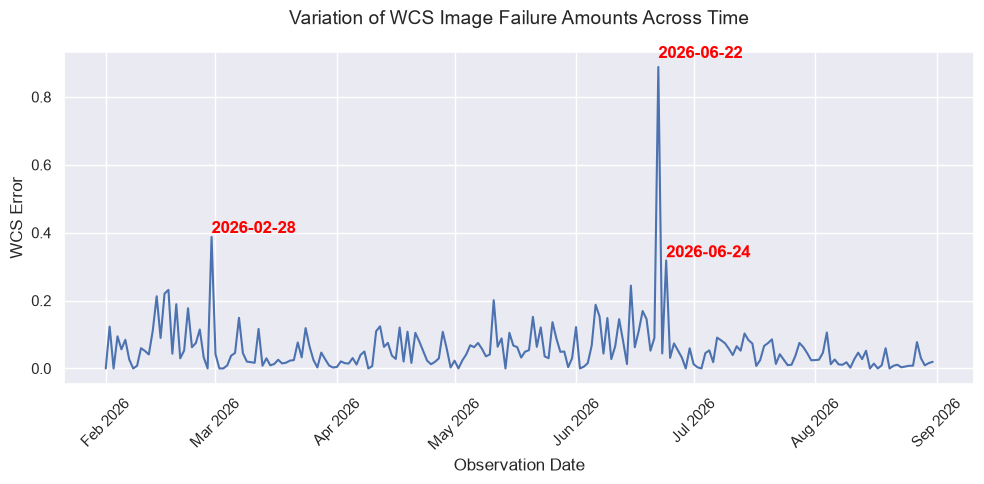

In [59]:
plt.figure(figsize=(10, 5))
sns.set_theme(style="darkgrid")

# Add this line right before your plotting code
result_df["observation_date"] = pd.to_datetime(result_df["observation_date"])


ax = sns.lineplot(data=result_df, x='observation_date', y='WCSERR')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1)) # Tick every month
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

outlier_dates = [pd.to_datetime("2026-06-22"), pd.to_datetime("2026-02-28"), pd.to_datetime("2026-06-24")]

for date in outlier_dates:
    # Look up the Y value automatically from your data
    y_val = result_df.loc[result_df["observation_date"] == date, "WCSERR"].values[0]
    
    # Format the date string cleanly for the label text
    date_str = date.strftime('%Y-%m-%d')
    
    # Place a text box with an arrow pointing to the point
    ax.annotate(
        text=f"{date_str}",
        xy=(date, y_val),           # Arrow points here
        xytext=(date, y_val * 1.03),  # Text box location (offset upwards)
        horizontalalignment='left',
        color='red',
        weight='bold'
    )


plt.title("Variation of WCS Image Failure Amounts Across Time", fontsize=14, pad=20)
plt.xlabel("Observation Date", fontsize=12)
plt.ylabel("WCS Error", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()
